# Where should I open my nasi padang shop in 2060?

**Premise.** We want to open a nasi padang shop somewhere in the world that will still be thriving in 2060.
Which country offers the best mix of customers, rice and beef supply, and a kitchen that keeps running,
once a hotter, wetter, more regulated climate is priced in?

**Dataset.** World Bank climate change data (course dataset): 58 indicators for 218 countries, 1990-2011,
plus climate projections for 2045-2065. No external data is used; every feature is derived from this one file.

**ML type.** A combination:
1. **Imputation (regression)** - a denoising autoencoder fills genuinely missing values (new learning: neural networks).
2. **Clustering** - groups countries into market types.
3. **Ranking** - a transparent score with a weight-sensitivity check.

## 0. Setup

In [1]:
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from adjustText import adjust_text
from matplotlib.colors import LinearSegmentedColormap
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*xlrd engine is deprecated.*")

DATA = Path("data/climate_change.xls")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
SEED = 42

# Reference palette (dataviz skill): categorical slots in fixed order, plus chart chrome
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#104281", "#3987e5", "#f0efec", "#e66767", "#a12a2a"])
GOOD_BAD = DIV.reversed()  # blue = good for the shop, red = bad

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": AXIS, "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
})


def titled(ax, title, subtitle=None):
    """Bold left-aligned title with an optional muted subtitle underneath."""
    ax.set_title(title, pad=24 if subtitle else 8)
    if subtitle:
        ax.annotate(subtitle, xy=(0, 1), xycoords="axes fraction", xytext=(0, 7), textcoords="offset points",
                    fontsize=9, color=INK_2, va="bottom")


def label_points(ax, xs, ys, labels):
    """Direct labels nudged apart so they never overlap each other or the points."""
    texts = [ax.text(x, y, t, fontsize=8, color=INK_2) for x, y, t in zip(xs, ys, labels)]
    adjust_text(texts, x=list(xs), y=list(ys), ax=ax, expand=(1.3, 1.8),
                arrowprops={"arrowstyle": "-", "color": AXIS, "lw": 0.6})


def save(fig, name):
    """Save a slide-ready figure with a source footnote placed below everything else."""
    fig.canvas.draw()
    bottom = fig.get_tightbbox(fig.canvas.get_renderer()).y0 / fig.get_figheight()
    fig.text(0.01, bottom - 0.01, "Source: World Bank climate change data (MA0218 course dataset)",
             fontsize=7, color=MUTED, va="top")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 1. Load and reshape

The workbook has three sheets: `Data` (one row per country x indicator, one column per year), `Country`
(income group and region) and `Series` (indicator definitions). Regional aggregates such as "Euro area"
are removed so that every row is a real country. Missing values are coded as the text `..`.

In [2]:
raw = pd.read_excel(DATA, sheet_name="Data")
meta = pd.read_excel(DATA, sheet_name="Country")
meta = meta[meta["Region"] != "Aggregates"].set_index("Country code")
raw = raw[raw["Country code"].isin(meta.index)]

YEARS = [c for c in raw.columns if str(c).isdigit()]
wide = raw.set_index(["Country code", "Series name"])[YEARS].replace("..", np.nan)
names = meta["Country name"]

print(f"{len(meta)} countries x {raw['Series name'].nunique()} indicators x {len(YEARS)} years "
      f"({YEARS[0]}-{YEARS[-1]})")

218 countries x 58 indicators x 22 years (1990-2011)


In [3]:
def ts(name):
    """Country x year table of a numeric indicator."""
    return wide.xs(name, level="Series name").apply(pd.to_numeric, errors="coerce")


def latest(name):
    """Most recent reported value per country."""
    return ts(name).ffill(axis=1).iloc[:, -1]


def text(name):
    """Most recent raw (text) value per country, for snapshot indicators stored as strings."""
    return wide.xs(name, level="Series name").ffill(axis=1).iloc[:, -1]


def midpoint(name, sep):
    """Parse 'a to b' or 'a / b' strings and return the midpoint."""
    parts = text(name).astype("string").str.extract(rf"(-?[\d.]+)\s*{sep}\s*(-?[\d.]+)").astype(float)
    return parts.mean(axis=1)

## 2. Exploratory analysis: how empty is this dataset?

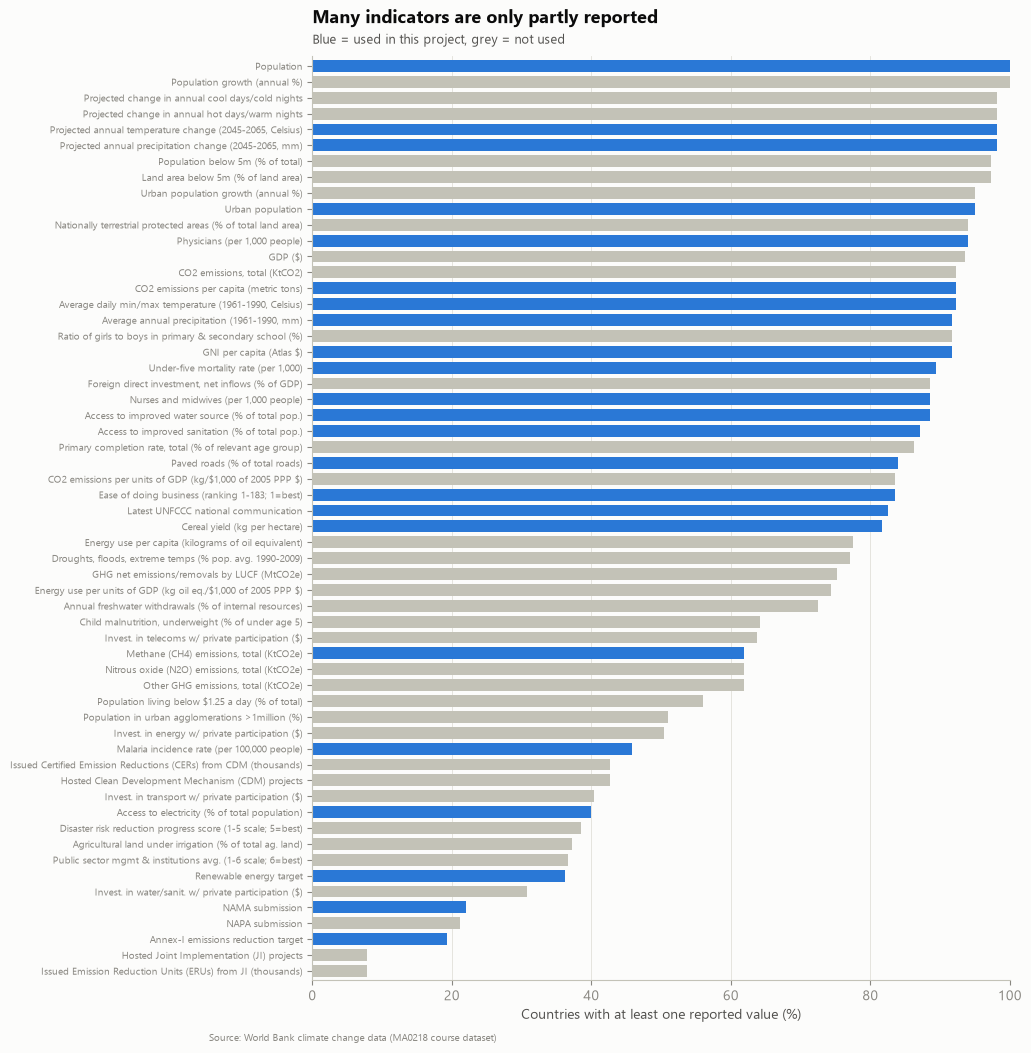

Median indicator coverage: 82%; 15 of 58 indicators cover fewer than half of countries


In [4]:
coverage = wide.notna().any(axis=1).groupby(level="Series name").mean().sort_values()

USED = {
    "Population", "Urban population", "GNI per capita (Atlas $)", "Methane (CH4) emissions, total (KtCO2e)",
    "Cereal yield (kg per hectare)", "Average annual precipitation (1961-1990, mm)",
    "Projected annual precipitation change (2045-2065, mm)", "Average daily min/max temperature (1961-1990, Celsius)",
    "Projected annual temperature change (2045-2065, Celsius)", "Access to electricity (% of total population)",
    "Paved roads (% of total roads)", "Access to improved water source (% of total pop.)",
    "Access to improved sanitation (% of total pop.)", "Physicians (per 1,000 people)",
    "Nurses and midwives (per 1,000 people)", "Malaria incidence rate (per 100,000 people)",
    "Ease of doing business (ranking 1-183; 1=best)", "Annex-I emissions reduction target",
    "Renewable energy target", "NAMA submission", "Latest UNFCCC national communication",
    "CO2 emissions per capita (metric tons)", "Under-five mortality rate (per 1,000)",
}

fig, ax = plt.subplots(figsize=(9, 12))
colors = [CAT[0] if s in USED else AXIS for s in coverage.index]
ax.barh(range(len(coverage)), coverage.values * 100, color=colors, height=0.75)
ax.set_yticks(range(len(coverage)), coverage.index.str.replace("$", r"\$", regex=False), fontsize=7.5)
ax.set_xlabel("Countries with at least one reported value (%)")
ax.set_xlim(0, 100)
ax.set_ylim(-0.6, len(coverage) - 0.4)
ax.grid(axis="y", visible=False)
titled(ax, "Many indicators are only partly reported", "Blue = used in this project, grey = not used")
save(fig, "01_indicator_coverage")

print(f"Median indicator coverage: {coverage.median():.0%}; "
      f"{(coverage < 0.5).sum()} of {len(coverage)} indicators cover fewer than half of countries")

### Not every blank means "unknown"

Coverage differs sharply by income group. Some indicators are simply not collected where they do not apply:

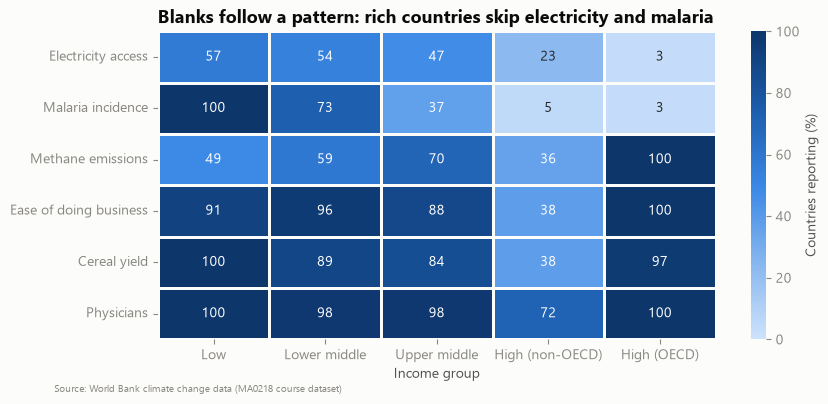

In [5]:
CHECK = {
    "Access to electricity (% of total population)": "Electricity access",
    "Malaria incidence rate (per 100,000 people)": "Malaria incidence",
    "Methane (CH4) emissions, total (KtCO2e)": "Methane emissions",
    "Ease of doing business (ranking 1-183; 1=best)": "Ease of doing business",
    "Cereal yield (kg per hectare)": "Cereal yield",
    "Physicians (per 1,000 people)": "Physicians",
}
INCOME_ORDER = ["Low income", "Lower middle income", "Upper middle income", "High income: nonOECD",
                "High income: OECD"]
by_income = pd.DataFrame({
    label: wide.xs(series, level="Series name").notna().any(axis=1).groupby(meta["Income group"]).mean()
    for series, label in CHECK.items()
}).T[INCOME_ORDER] * 100

fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(by_income, annot=True, fmt=".0f", cmap=SEQ, vmin=0, vmax=100, linewidths=2, linecolor=SURFACE,
            cbar_kws={"label": "Countries reporting (%)"}, ax=ax)
ax.set_xticklabels(["Low", "Lower middle", "Upper middle", "High (non-OECD)", "High (OECD)"], rotation=0)
ax.set_xlabel("Income group")
ax.set_ylabel("")
ax.grid(False)
ax.set_title("Blanks follow a pattern: rich countries skip electricity and malaria")
save(fig, "02_missingness_by_income")

This leads to **three kinds of blanks**, each handled differently:

| Kind of blank | Example | Treatment |
|---|---|---|
| Means **"no"** | Climate-commitment flags, malaria in non-endemic countries | Fill with 0 / "no" |
| Means **"obviously ~100%"** | Electricity access in high-income countries | Fill with 100% by rule (stated assumption) |
| **Genuinely unknown** | Methane, cereal yield, ease of doing business | Neural-network imputation (section 4) |

Imputing the first two kinds would invent information (for example, fake climate pledges), so they are filled by rule first.

## 3. Build the country table

Snapshot indicators (climate projections, baseline temperature) are stored as text such as `"1.5 to 2.1"`
(a range across climate models) or `"5.5 / 19.7"` (daily min / max); we take the midpoint.

In [6]:
f = pd.DataFrame(index=meta.index)

# Demand
f["population"] = latest("Population")
f["urban_pop"] = latest("Urban population")
f["gni_pc"] = latest("GNI per capita (Atlas $)")

# Supply: methane per person (methane is only reported for 1990/1995/2000/2005, so use 2005)
f["methane_pc"] = ts("Methane (CH4) emissions, total (KtCO2e)")[2005] * 1000 / ts("Population")[2005]

# Supply: cereal yield trend (% per year) and volatility (std of year-on-year % change), needs >= 10 years
log_yield = np.log(ts("Cereal yield (kg per hectare)"))
year_num = np.array([int(y) for y in log_yield.columns])


def trend(row):
    ok = row.notna().values
    return np.polyfit(year_num[ok], row.values[ok], 1)[0] * 100 if ok.sum() >= 10 else np.nan


enough = log_yield.notna().sum(axis=1) >= 10
f["yield_trend"] = log_yield.apply(trend, axis=1)
f["yield_volatility"] = (log_yield.diff(axis=1).std(axis=1) * 100).where(enough)

# Climate: relative rainfall shift and absolute 2060 temperature
f["rain_shift"] = (midpoint("Projected annual precipitation change (2045-2065, mm)", "to")
                   / latest("Average annual precipitation (1961-1990, mm)"))
f["temp_2060"] = (midpoint("Average daily min/max temperature (1961-1990, Celsius)", "/")
                  + midpoint("Projected annual temperature change (2045-2065, Celsius)", "to"))

# Kitchen and operations
f["electricity"] = latest("Access to electricity (% of total population)")
f["paved_roads"] = latest("Paved roads (% of total roads)")
f["water"] = latest("Access to improved water source (% of total pop.)")
f["sanitation"] = latest("Access to improved sanitation (% of total pop.)")
f["physicians"] = latest("Physicians (per 1,000 people)")
f["nurses"] = latest("Nurses and midwives (per 1,000 people)")
f["malaria"] = latest("Malaria incidence rate (per 100,000 people)")
f["ease_rank"] = latest("Ease of doing business (ranking 1-183; 1=best)")

# Helpers for imputation only (well-covered development indicators)
f["co2_pc"] = latest("CO2 emissions per capita (metric tons)")
f["u5_mortality"] = latest("Under-five mortality rate (per 1,000)")

# Climate commitments (text flags)
f["annex1_target"] = text("Annex-I emissions reduction target").notna().astype(int)
f["renewable_target"] = text("Renewable energy target").notna().astype(int)
f["nama"] = text("NAMA submission").notna().astype(int)
f["unfccc_reports"] = (text("Latest UNFCCC national communication").astype("string")
                       .str.extract(r"\((\d)")[0].astype(float))

### Apply the rule-based fills (blanks that mean "no" or "~100%")

In [7]:
rich = meta["Income group"].str.startswith("High income")
before = f["electricity"].isna().sum()
f.loc[rich & f["electricity"].isna(), "electricity"] = 100.0
f["malaria"] = f["malaria"].fillna(0.0)
f["unfccc_reports"] = f["unfccc_reports"].fillna(0.0)
print(f"Electricity: {before} blanks -> {f['electricity'].isna().sum()} after filling high-income countries at 100%")
print("Malaria and commitment blanks filled with 0")

Electricity: 131 blanks -> 71 after filling high-income countries at 100%
Malaria and commitment blanks filled with 0


## 4. Neural-network imputation (new learning)

The remaining blanks are genuinely unknown. We fill them with a **denoising autoencoder**:
a neural network that is shown each country's indicators with extra values deliberately hidden, and learns
to reconstruct them from the values that remain. Because it learns non-linear relationships between
indicators (for example, rich countries have more physicians *and* better roads *and* lower child mortality),
it can fill a gap using everything else known about that country.

Countries missing more than 40% of the inputs (mostly tiny territories such as Gibraltar and Tuvalu) are
dropped, since there would be too little to learn from.

In [8]:
IMPUTE = ["urban_pop", "gni_pc", "methane_pc", "co2_pc", "u5_mortality", "yield_trend", "yield_volatility",
          "rain_shift", "temp_2060", "electricity", "paved_roads", "water", "sanitation", "physicians", "nurses",
          "ease_rank"]
LOG = ["urban_pop", "gni_pc", "methane_pc", "co2_pc", "u5_mortality", "physicians", "nurses"]

X = f[IMPUTE].copy()
X[LOG] = np.log(X[LOG])
observed_share = X.notna().mean(axis=1)
dropped = names[observed_share < 0.6]
X = X[observed_share >= 0.6]
print(f"Kept {len(X)} countries, dropped {len(dropped)}: {', '.join(dropped)}")
print(f"Blanks left to impute: {int(X.isna().sum().sum())} of {X.size} values ({X.isna().mean().mean():.1%})")

scaler = StandardScaler()
Z = pd.DataFrame(scaler.fit_transform(X), index=X.index, columns=X.columns)

Kept 190 countries, dropped 28: Aruba, American Samoa, Bermuda, Channel Islands, Cook Islands, Curacao, Cayman Islands, Faeroe Islands, Gibraltar, Greenland, Guam, Isle of Man, Kosovo, Liechtenstein, Macao SAR, China, St. Martin (French part), Montenegro, Northern Mariana Islands, Mayotte, New Caledonia, Niue, Nauru, French Polynesia, San Marino, Sint Maarten (Dutch part), Turks and Caicos Islands, Tuvalu, Virgin Islands (U.S.)
Blanks left to impute: 207 of 3040 values (6.8%)


In [9]:
def autoencoder_impute(Zm, hidden=64, latent=8, drop=0.3, epochs=1500, n_models=5, seed=SEED):
    """Denoising autoencoder imputer.

    Input = values (blanks set to 0) concatenated with the observed-mask, so the network knows what is missing.
    Each epoch hides a random 30% of the observed values and trains the network to reconstruct them;
    the loss is computed only on values that are truly observed. Five networks are averaged for stability.
    """
    mask = ~np.isnan(Zm)
    x = torch.tensor(np.nan_to_num(Zm), dtype=torch.float32)
    m = torch.tensor(mask, dtype=torch.float32)
    d = x.shape[1]
    preds = []
    for i in range(n_models):
        torch.manual_seed(seed + i)
        net = torch.nn.Sequential(
            torch.nn.Linear(2 * d, hidden), torch.nn.ReLU(),
            torch.nn.Linear(hidden, latent), torch.nn.ReLU(),
            torch.nn.Linear(latent, hidden), torch.nn.ReLU(),
            torch.nn.Linear(hidden, d),
        )
        opt = torch.optim.Adam(net.parameters(), lr=3e-3, weight_decay=1e-3)
        for _ in range(epochs):
            keep = (torch.rand_like(m) > drop).float() * m
            out = net(torch.cat([x * keep, keep], dim=1))
            loss = (((out - x) ** 2) * m).sum() / m.sum()
            opt.zero_grad()
            loss.backward()
            opt.step()
        with torch.no_grad():
            preds.append(net(torch.cat([x * m, m], dim=1)).numpy())
    return np.where(mask, Zm, np.mean(preds, axis=0))


IMPUTERS = {
    "Column mean": lambda Zm: SimpleImputer().fit_transform(Zm),
    "KNN (10 neighbours)": lambda Zm: KNNImputer(n_neighbors=10, weights="distance").fit_transform(Zm),
    "Iterative MLP": lambda Zm: IterativeImputer(
        MLPRegressor(hidden_layer_sizes=(8,), alpha=20.0, solver="lbfgs", max_iter=300, random_state=SEED),
        max_iter=5, random_state=SEED).fit_transform(Zm),
    "Denoising autoencoder": autoencoder_impute,
}

### Which imputer is most accurate?

Test: hide 15% of the values we *do* know, impute them, and measure the error against the truth
(RMSE in standard deviations, so 1.0 = no better than guessing the average). Hyperparameters were tuned on
separate random masks; the five masks below are fresh, so the comparison is not flattered.

In [10]:
Zv = Z.values
observed_idx = np.argwhere(~np.isnan(Zv))
errors = {name: [] for name in IMPUTERS}
for seed in range(100, 105):
    rng = np.random.default_rng(seed)
    hide = observed_idx[rng.choice(len(observed_idx), int(0.15 * len(observed_idx)), replace=False)]
    Zm = Zv.copy()
    Zm[hide[:, 0], hide[:, 1]] = np.nan
    truth = Zv[hide[:, 0], hide[:, 1]]
    for name, impute in IMPUTERS.items():
        guess = impute(Zm)[hide[:, 0], hide[:, 1]]
        errors[name].append(np.sqrt(np.mean((guess - truth) ** 2)))

bench = pd.DataFrame(errors).agg(["mean", "std"]).T
print(bench.round(3))

                        mean    std
Column mean            0.993  0.061
KNN (10 neighbours)    0.704  0.048
Iterative MLP          0.695  0.053
Denoising autoencoder  0.685  0.045


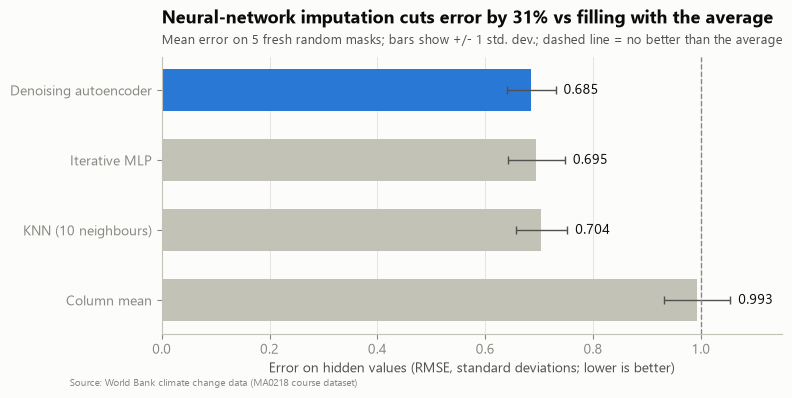

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.6))
order = bench["mean"].sort_values(ascending=False).index
best = bench["mean"].idxmin()
bar_colors = [CAT[0] if n == best else AXIS for n in order]
ax.barh(order, bench.loc[order, "mean"], xerr=bench.loc[order, "std"], color=bar_colors, height=0.6,
        error_kw={"ecolor": INK_2, "capsize": 3, "lw": 1})
for i, n in enumerate(order):
    ax.text(bench.loc[n, "mean"] + bench.loc[n, "std"] + 0.015, i, f"{bench.loc[n, 'mean']:.3f}",
            va="center", color=INK, fontsize=10)
ax.axvline(1.0, color=MUTED, lw=1, ls="--")
ax.set_xlim(0, 1.15)
ax.set_xlabel("Error on hidden values (RMSE, standard deviations; lower is better)")
ax.grid(axis="y", visible=False)
cut = 1 - bench.loc[best, "mean"] / bench.loc["Column mean", "mean"]
titled(ax, f"Neural-network imputation cuts error by {cut:.0%} vs filling with the average",
       "Mean error on 5 fresh random masks; bars show +/- 1 std. dev.; dashed line = no better than the average")
save(fig, "03_imputation_benchmark")

Fill all genuine blanks with the winning imputer, then undo the scaling and log transforms.

In [12]:
best_imputer = IMPUTERS[best]
filled = pd.DataFrame(scaler.inverse_transform(best_imputer(Zv)), index=Z.index, columns=Z.columns)
filled[LOG] = np.exp(filled[LOG])
was_imputed = X.isna()

d = f.loc[filled.index].copy()
d[IMPUTE] = filled
d["electricity"] = d["electricity"].clip(0, 100)
d[["water", "sanitation", "paved_roads"]] = d[["water", "sanitation", "paved_roads"]].clip(0, 100)
d["ease_rank"] = d["ease_rank"].clip(1, 183)
print(f"Imputed with: {best}. Final table: {d.shape[0]} countries, no missing inputs: {not d[IMPUTE].isna().any().any()}")

Imputed with: Denoising autoencoder. Final table: 190 countries, no missing inputs: True


## 5. Engineered features

| Group | Feature | Built from | Direction |
|---|---|---|---|
| Demand | Urban customers | Urban population (log) | higher = better |
| Demand | Spending power | GNI per capita (log) | higher = better |
| Rice and beef supply | Methane per person | Methane / population: proxy for paddies and cattle | higher = better |
| Rice and beef supply | Yield trend | Growth of cereal yield, 1990-2011 | higher = better |
| Rice and beef supply | Yield volatility | Year-to-year swings in cereal yield | lower = better |
| Rice and beef supply | Rainfall shift | Projected rainfall change / baseline rainfall | wetter = better |
| Climate and policy | Beef-tax risk | Methane per person (percentile) x climate-commitment score | lower = better |
| Climate and policy | Rendang advantage | 2060 temperature (percentile) x share without electricity | higher = better |
| Kitchen and operations | Infrastructure | First principal component of paved roads, water, sanitation | higher = better |
| Kitchen and operations | Staff health | Physicians, nurses, (minus) malaria | higher = better |
| Kitchen and operations | Ease of doing business | Inverted ranking (1 = best becomes 1.0) | higher = better |

In [13]:
def pct(s):
    return s.rank(pct=True)


def zscore(s):
    return (s - s.mean()) / s.std()


# Climate-commitment score in [0, 1]: three yes/no flags + number of UNFCCC reports (max 5)
d["commitment"] = (d["annex1_target"] + d["renewable_target"] + d["nama"] + d["unfccc_reports"] / 5) / 4
d["beef_tax_risk"] = pct(d["methane_pc"]) * d["commitment"]

# Rendang keeps without refrigeration: an edge where it is hot and the power is unreliable
d["rendang_advantage"] = pct(d["temp_2060"]) * (1 - d["electricity"] / 100)

infra_inputs = d[["paved_roads", "water", "sanitation"]]
infra_pca = PCA(n_components=1).fit(StandardScaler().fit_transform(infra_inputs))
pc1 = infra_pca.transform(StandardScaler().fit_transform(infra_inputs))[:, 0]
d["infrastructure"] = pc1 * np.sign(np.corrcoef(pc1, d["water"])[0, 1])
print(f"Infrastructure index explains {infra_pca.explained_variance_ratio_[0]:.0%} of the variance of its 3 inputs")

d["staff_health"] = (zscore(np.log(d["physicians"])) + zscore(np.log(d["nurses"]))
                     - zscore(np.log1p(d["malaria"]))) / 3
d["ease_score"] = 1 - (d["ease_rank"] - 1) / 182
d["log_urban_pop"] = np.log10(d["urban_pop"])
d["log_gni_pc"] = np.log10(d["gni_pc"])

FEATURES = {
    "Demand": {"log_urban_pop": +1, "log_gni_pc": +1},
    "Rice and beef supply": {"methane_pc": +1, "yield_trend": +1, "yield_volatility": -1, "rain_shift": +1},
    "Climate and policy": {"beef_tax_risk": -1, "rendang_advantage": +1},
    "Kitchen and operations": {"infrastructure": +1, "staff_health": +1, "ease_score": +1},
}
LABELS = {
    "log_urban_pop": "Urban customers", "log_gni_pc": "Spending power", "methane_pc": "Methane per person",
    "yield_trend": "Yield trend", "yield_volatility": "Yield volatility", "rain_shift": "Rainfall shift",
    "beef_tax_risk": "Beef-tax risk", "rendang_advantage": "Rendang advantage", "infrastructure": "Infrastructure",
    "staff_health": "Staff health", "ease_score": "Ease of doing business",
}
FEATURE_COLS = [c for group in FEATURES.values() for c in group]
d["name"] = names.loc[d.index]
d[FEATURE_COLS].describe().T.round(2)

Infrastructure index explains 79% of the variance of its 3 inputs


,count,mean,std,min,25%,50%,75%,max
log_urban_pop,190.0,6.49,0.92,4.23,6.05,6.57,7.06,8.78
log_gni_pc,190.0,3.63,0.67,2.18,3.08,3.64,4.10,5.26
methane_pc,190.0,1.75,2.24,0.20,0.66,1.10,1.76,19.13
yield_trend,190.0,1.29,1.64,-4.64,0.34,1.22,2.22,6.79
yield_volatility,190.0,18.06,16.47,1.66,8.55,13.65,21.90,133.61
rain_shift,190.0,-0.02,0.08,-0.57,-0.05,-0.01,0.03,0.19
beef_tax_risk,190.0,0.16,0.18,0.00,0.03,0.07,0.24,0.73
rendang_advantage,190.0,0.17,0.23,0.00,0.00,0.04,0.27,0.91
infrastructure,190.0,0.00,1.54,-3.56,-1.25,0.34,1.38,1.87
staff_health,190.0,0.00,0.92,-2.06,-0.76,0.20,0.79,1.25


### Rendang advantage: where heat and unreliable power favour nasi padang

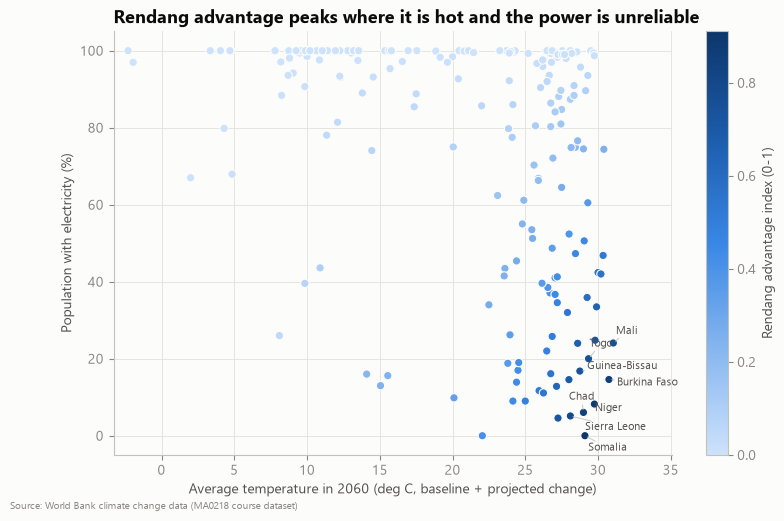

In [14]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sc = ax.scatter(d["temp_2060"], d["electricity"], c=d["rendang_advantage"], cmap=SEQ, s=36,
                edgecolor=SURFACE, linewidth=0.8)
top_rendang = d.nlargest(8, "rendang_advantage")
ax.set_xlim(d["temp_2060"].min() - 1, d["temp_2060"].max() + 4)
label_points(ax, top_rendang["temp_2060"], top_rendang["electricity"], top_rendang["name"])
ax.set_xlabel("Average temperature in 2060 (deg C, baseline + projected change)")
ax.set_ylabel("Population with electricity (%)")
fig.colorbar(sc, ax=ax, label="Rendang advantage index (0-1)")
ax.set_title("Rendang advantage peaks where it is hot and the power is unreliable")
save(fig, "04_rendang_advantage")

### EDA check: is methane really a rice-and-cattle proxy?

Total methane also includes leaks from oil, gas and coal. Plotting methane per person against CO2 per person
separates the two stories: countries in the top 15% for methane **and** the top 10% for CO2 are likely
fossil-fuel producers, where the proxy is weak. (The CO2 cut-off is deliberately strict: at the top 15%,
cattle-farming Ireland would be wrongly flagged.)

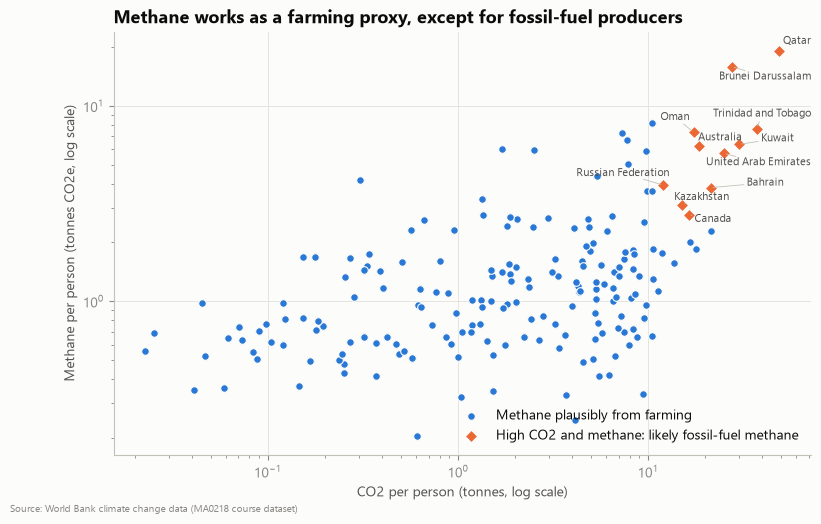

Flagged as likely fossil-fuel methane: United Arab Emirates, Australia, Bahrain, Brunei Darussalam, Canada, Kazakhstan, Kuwait, Oman, Qatar, Russian Federation, Trinidad and Tobago


In [15]:
fig, ax = plt.subplots(figsize=(9, 5.5))
fossil = (pct(d["co2_pc"]) > 0.90) & (pct(d["methane_pc"]) > 0.85)
ax.scatter(d.loc[~fossil, "co2_pc"], d.loc[~fossil, "methane_pc"], s=30, color=CAT[0], edgecolor=SURFACE,
           linewidth=0.8, label="Methane plausibly from farming")
ax.scatter(d.loc[fossil, "co2_pc"], d.loc[fossil, "methane_pc"], s=40, color=CAT[1], marker="D",
           edgecolor=SURFACE, linewidth=0.8, label="High CO2 and methane: likely fossil-fuel methane")
ax.set_xscale("log")
ax.set_yscale("log")
label_points(ax, d.loc[fossil, "co2_pc"], d.loc[fossil, "methane_pc"], d.loc[fossil, "name"])
ax.set_xlabel("CO2 per person (tonnes, log scale)")
ax.set_ylabel("Methane per person (tonnes CO2e, log scale)")
ax.legend(frameon=False, loc="lower right")
ax.set_title("Methane works as a farming proxy, except for fossil-fuel producers")
save(fig, "05_methane_proxy_check")
print("Flagged as likely fossil-fuel methane:", ", ".join(d.loc[fossil, "name"]))

**Treatment:** for the flagged countries, methane does not signal local rice and cattle, so their
methane-per-person *supply* score is set to the median (neutral). Their beef-tax risk is kept, because
a methane-heavy economy with climate pledges is still likely to regulate methane.

In [16]:
d["methane_supply"] = d["methane_pc"].where(~fossil, d["methane_pc"].median())
FEATURES["Rice and beef supply"] = {"methane_supply": +1, **{k: v for k, v in
                                    FEATURES["Rice and beef supply"].items() if k != "methane_pc"}}
LABELS["methane_supply"] = "Methane per person"
FEATURE_COLS = [c for group in FEATURES.values() for c in group]

### Beef-tax risk: methane-heavy countries that have promised to cut emissions

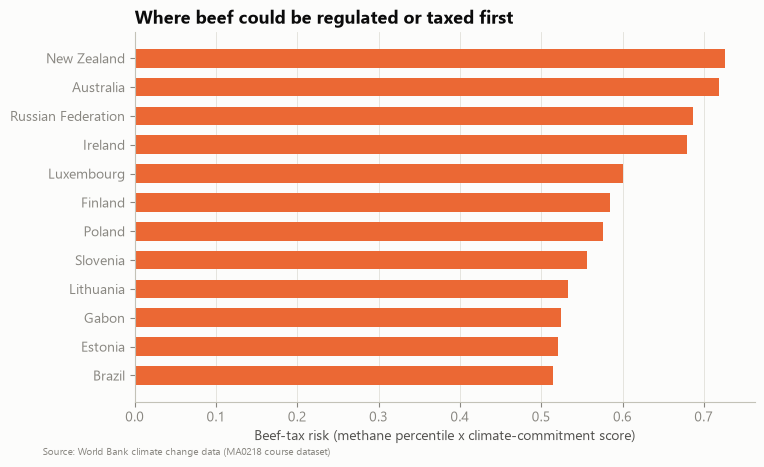

In [17]:
top_risk = d.nlargest(12, "beef_tax_risk").iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(top_risk["name"], top_risk["beef_tax_risk"], color=CAT[1], height=0.65)
ax.set_xlabel("Beef-tax risk (methane percentile x climate-commitment score)")
ax.grid(axis="y", visible=False)
ax.set_title("Where beef could be regulated or taxed first")
save(fig, "06_beef_tax_risk")

### Are the features telling us different things?

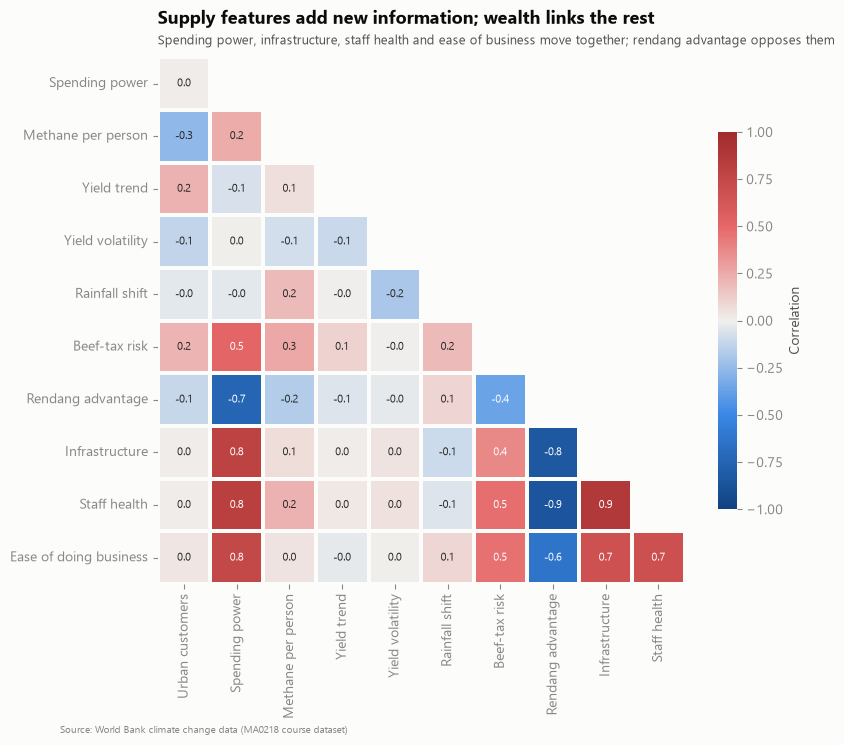

Pairs with |r| > 0.7: {('Spending power', 'Rendang advantage'): -0.74, ('Spending power', 'Infrastructure'): 0.79, ('Spending power', 'Staff health'): 0.81, ('Spending power', 'Ease of doing business'): 0.75, ('Rendang advantage', 'Infrastructure'): -0.84, ('Rendang advantage', 'Staff health'): -0.86, ('Infrastructure', 'Staff health'): 0.87}


In [18]:
corr = d[FEATURE_COLS].rename(columns=LABELS).corr()
lower = corr.iloc[1:, :-1]  # drop the empty first row / last column left by hiding the diagonal
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(lower, mask=np.triu(np.ones_like(lower, dtype=bool), k=1), cmap=DIV, vmin=-1, vmax=1, annot=True,
            fmt=".1f", annot_kws={"size": 8}, linewidths=1.5, linecolor=SURFACE, square=True,
            cbar_kws={"label": "Correlation", "shrink": 0.7}, ax=ax)
ax.grid(False)
titled(ax, "Supply features add new information; wealth links the rest",
       "Spending power, infrastructure, staff health and ease of business move together; rendang advantage opposes them")
save(fig, "07_feature_correlation")

strong = corr.where(np.triu(np.ones_like(corr, dtype=bool), k=1)).stack()
print("Pairs with |r| > 0.7:", strong[strong.abs() > 0.7].round(2).to_dict())

**Reading the correlations.** The wealth-related features (spending power, infrastructure, staff health, ease of
doing business) are strongly correlated, and rendang advantage is their mirror image: it is high exactly where
countries are poor. In the ranking, these features sit in different groups, so the score is a deliberate trade-off
between "rich and easy to operate in" and "hot, under-served and rendang-friendly". The supply features
(yield trend, volatility, rainfall shift) are almost uncorrelated with everything else and add genuinely new information.

## 6. Clustering: market types

### Model selection (internal, not for slides)

Two algorithms are candidates: **K-means** (hard, spherical clusters) and a **Gaussian mixture**
(soft, elliptical clusters). Rather than presenting the comparison, we use it to decide which one goes into the
presentation. The decision rule, fixed before looking at the results:
1. only consider 3-7 clusters (fewer is too coarse for a market-entry story; more is too many to explain in 10 minutes);
2. require **stability**: refitting on random 80% subsamples must reproduce the clustering (mean adjusted Rand index >= 0.6);
3. require every cluster to hold at least 8 countries;
4. among the survivors, pick the highest **silhouette** score (how well separated the clusters are).

In [19]:
signed = pd.DataFrame({c: d[c] * s for g in FEATURES.values() for c, s in g.items()}, index=d.index)
C = StandardScaler().fit_transform(signed)


def make_model(kind, k, seed):
    if kind == "K-means":
        return KMeans(n_clusters=k, n_init=20, random_state=seed)
    return GaussianMixture(n_components=k, covariance_type=kind.split("(")[1].rstrip(")"), n_init=5,
                           random_state=seed)


def stability(kind, k, runs=15):
    ref = make_model(kind, k, SEED).fit(C).predict(C)
    rng = np.random.default_rng(SEED)
    scores = []
    for r in range(runs):
        idx = rng.choice(len(C), int(0.8 * len(C)), replace=False)
        scores.append(adjusted_rand_score(ref, make_model(kind, k, r).fit(C[idx]).predict(C)))
    return np.mean(scores)


rows = []
for kind in ["K-means", "Gaussian mixture (diag)", "Gaussian mixture (tied)"]:
    for k in range(3, 8):
        labels = make_model(kind, k, SEED).fit(C).predict(C)
        rows.append({
            "model": kind, "k": k,
            "silhouette": silhouette_score(C, labels),
            "davies_bouldin": davies_bouldin_score(C, labels),
            "stability_ari": stability(kind, k),
            "smallest_cluster": np.bincount(labels, minlength=k).min(),
        })
selection = pd.DataFrame(rows)
selection["eligible"] = (selection["stability_ari"] >= 0.6) & (selection["smallest_cluster"] >= 8)
print(selection.round(3).to_string(index=False))

                  model  k  silhouette  davies_bouldin  stability_ari  smallest_cluster  eligible
                K-means  3       0.197           1.790          0.688                51      True
                K-means  4       0.205           1.667          0.814                34      True
                K-means  5       0.211           1.548          0.709                13      True
                K-means  6       0.188           1.578          0.709                11      True
                K-means  7       0.176           1.475          0.614                 8      True
Gaussian mixture (diag)  3       0.174           1.994          0.886                48      True
Gaussian mixture (diag)  4       0.125           2.304          0.822                41      True
Gaussian mixture (diag)  5       0.075           2.748          0.629                28      True
Gaussian mixture (diag)  6       0.079           2.389          0.605                21      True
Gaussian mixture (di

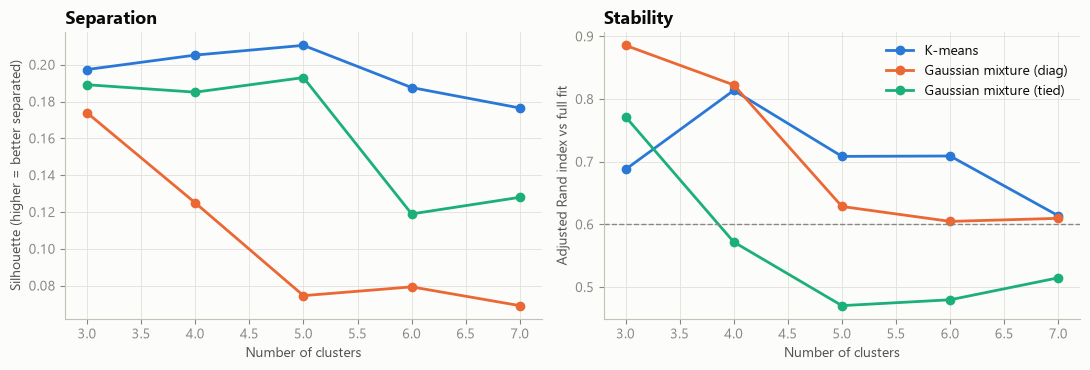

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for i, (kind, g) in enumerate(selection.groupby("model", sort=False)):
    axes[0].plot(g["k"], g["silhouette"], marker="o", color=CAT[i], lw=2, ms=6, label=kind)
    axes[1].plot(g["k"], g["stability_ari"], marker="o", color=CAT[i], lw=2, ms=6, label=kind)
axes[0].set(xlabel="Number of clusters", ylabel="Silhouette (higher = better separated)", title="Separation")
axes[1].set(xlabel="Number of clusters", ylabel="Adjusted Rand index vs full fit", title="Stability")
axes[1].axhline(0.6, color=MUTED, ls="--", lw=1)
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()  # internal diagnostic: intentionally not saved to figures/

In [21]:
eligible = selection[selection["eligible"]]
chosen = (eligible if len(eligible) else selection).sort_values("silhouette", ascending=False).iloc[0]
CHOSEN_MODEL, K = chosen["model"], int(chosen["k"])
print(f"Chosen: {CHOSEN_MODEL} with {K} clusters "
      f"(silhouette {chosen['silhouette']:.3f}, stability {chosen['stability_ari']:.2f})")

best_other = selection[(selection["model"] != CHOSEN_MODEL) & selection["eligible"]]
if len(best_other):
    other = best_other.sort_values("silhouette", ascending=False).iloc[0]
    other_labels = make_model(other["model"], int(other["k"]), SEED).fit(C).predict(C)
    chosen_labels = make_model(CHOSEN_MODEL, K, SEED).fit(C).predict(C)
    print(f"Agreement with best alternative ({other['model']}, k={int(other['k'])}): "
          f"ARI {adjusted_rand_score(chosen_labels, other_labels):.2f}")

Chosen: K-means with 5 clusters (silhouette 0.211, stability 0.71)
Agreement with best alternative (Gaussian mixture (tied), k=3): ARI 0.47


### Final clustering

In [22]:
model = make_model(CHOSEN_MODEL, K, SEED).fit(C)
raw_labels = model.predict(C)
# Number clusters by mean desirability (sum of signed z-scores), so cluster 1 is the most attractive
desirability = pd.Series(C.mean(axis=1)).groupby(raw_labels).mean().sort_values(ascending=False)
relabel = {old: new for new, old in enumerate(desirability.index, start=1)}
d["cluster"] = pd.Series(raw_labels, index=d.index).map(relabel)

profile = pd.DataFrame(C, index=d.index, columns=[LABELS[c] for c in signed.columns]).groupby(d["cluster"]).mean()
sizes = d["cluster"].value_counts().sort_index()
for c in profile.index:
    members = d[d["cluster"] == c].sort_values("population", ascending=False)["name"].head(6)
    print(f"Cluster {c} ({sizes[c]} countries): {', '.join(members)}")

Cluster 1 (39 countries): United States, Brazil, Russian Federation, Germany, France, United Kingdom
Cluster 2 (61 countries): China, India, Indonesia, Pakistan, Japan, Mexico
Cluster 3 (31 countries): Bolivia, Azerbaijan, Paraguay, Turkmenistan, Uruguay, Gabon
Cluster 4 (46 countries): Nigeria, Bangladesh, Ethiopia, Congo, Dem. Rep., Myanmar, Tanzania
Cluster 5 (13 countries): Morocco, Zimbabwe, Jordan, Moldova, Mauritania, Kuwait


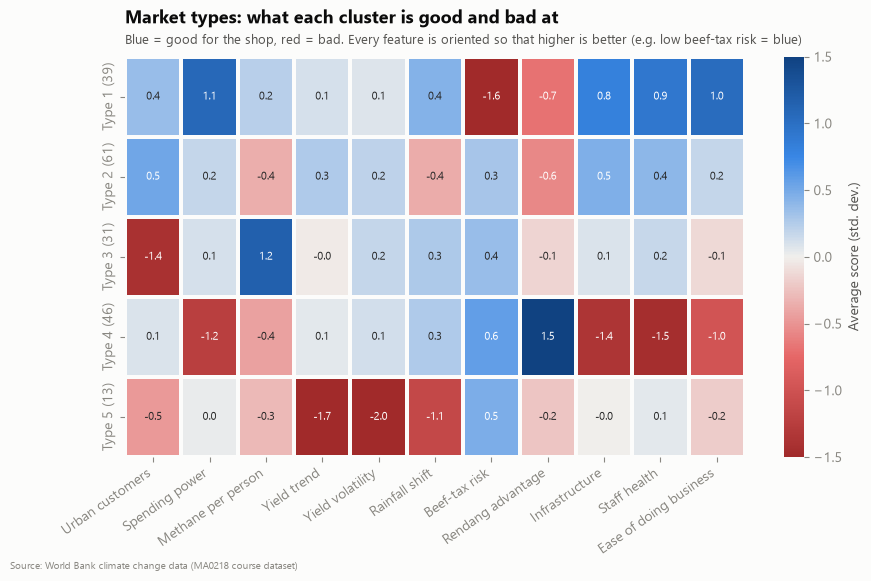

In [23]:
fig, ax = plt.subplots(figsize=(10, 0.6 * K + 2.2))
profile.index = [f"Type {c} ({sizes[c]})" for c in profile.index]
sns.heatmap(profile, cmap=GOOD_BAD, center=0, vmin=-1.5, vmax=1.5, annot=True, fmt=".1f", annot_kws={"size": 8},
            linewidths=1.5, linecolor=SURFACE, cbar_kws={"label": "Average score (std. dev.)"}, ax=ax)
ax.grid(False)
ax.set_ylabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha="right")
titled(ax, "Market types: what each cluster is good and bad at",
       "Blue = good for the shop, red = bad. Every feature is oriented so that higher is better (e.g. low beef-tax risk = blue)")
save(fig, "08_cluster_profiles")

**Naming the market types** (read off the profile above):

| Type | Name | Signature | Examples |
|---|---|---|---|
| 1 | Rich but regulated | Highest spending power and operations, but the highest beef-tax risk | United States, Germany, United Kingdom, France |
| 2 | Big-city all-rounders | Many urban customers, solid operations, low beef-tax risk; weaker local supply | China, India, Indonesia, Japan, Mexico |
| 3 | Cattle country, few customers | Highest methane per person (local beef and rice), but few city customers | Bolivia, Paraguay, Uruguay |
| 4 | Rendang frontier | Hot with unreliable power (big rendang advantage), but poor and hard to operate in | Nigeria, Bangladesh, Ethiopia, Myanmar |
| 5 | Fragile farms | Falling, volatile cereal yields and a drying climate | Morocco, Zimbabwe, Jordan, Moldova |

The clusters overlap (silhouette about 0.2), so they describe tendencies rather than hard boundaries.

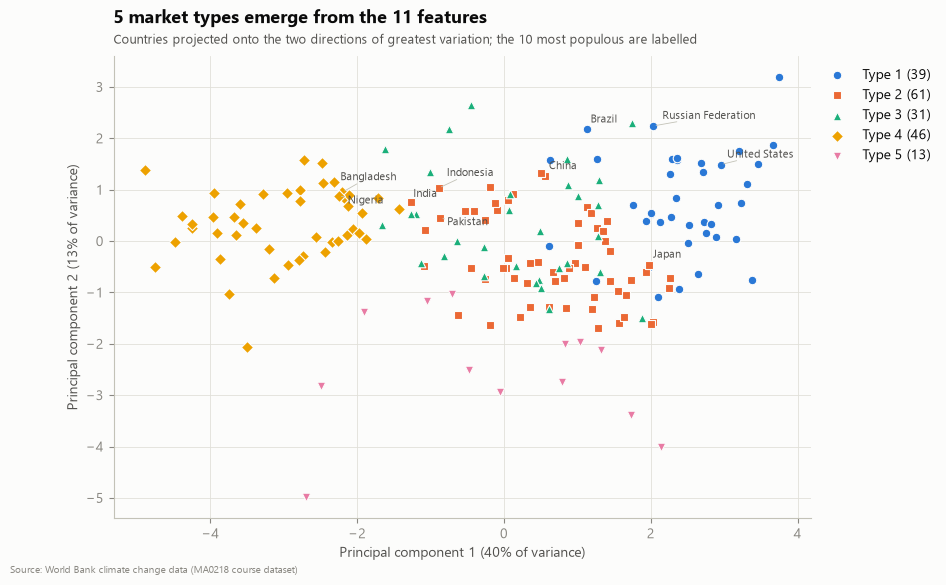

In [24]:
xy = PCA(n_components=2, random_state=SEED).fit(C)
P = xy.transform(C)
MARKERS = ["o", "s", "^", "D", "v", "P", "X"]
fig, ax = plt.subplots(figsize=(9, 6))
for c in sorted(d["cluster"].unique()):
    sel = (d["cluster"] == c).values
    ax.scatter(P[sel, 0], P[sel, 1], s=38, color=CAT[c - 1], marker=MARKERS[c - 1], edgecolor=SURFACE,
               linewidth=0.8, label=f"Type {c} ({sel.sum()})")
big = [d.index.get_loc(code) for code in d.nlargest(10, "population").index]
label_points(ax, P[big, 0], P[big, 1], d["name"].iloc[big])
ax.set_xlabel(f"Principal component 1 ({xy.explained_variance_ratio_[0]:.0%} of variance)")
ax.set_ylabel(f"Principal component 2 ({xy.explained_variance_ratio_[1]:.0%} of variance)")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
titled(ax, f"{K} market types emerge from the 11 features",
       "Countries projected onto the two directions of greatest variation; the 10 most populous are labelled")
save(fig, "09_cluster_map")

## 7. Ranking: where to open the shop

Only countries with at least 1 million people are ranked (a shop needs a market). Each feature is converted to a
percentile (flipped where lower is better), averaged within its group, and the four groups are weighted equally.

In [25]:
R = d[d["population"] >= 1e6].copy()
group_scores = pd.DataFrame(index=R.index)
for group, feats in FEATURES.items():
    parts = [pct(R[c]) if s > 0 else 1 - pct(R[c]) + 1 / len(R) for c, s in feats.items()]
    group_scores[group] = pd.concat(parts, axis=1).mean(axis=1)
GROUPS = list(FEATURES)
weights = np.full(len(GROUPS), 1 / len(GROUPS))
R["score"] = group_scores[GROUPS] @ weights
R["rank"] = R["score"].rank(ascending=False).astype(int)
R = R.sort_values("rank")
print(f"Ranked {len(R)} countries")
R[["name", "score", "cluster"]].head(10)

Ranked 156 countries


,name,score,cluster
Country code,,,
USA,United States,0.684562,1
OMN,Oman,0.654581,2
GBR,United Kingdom,0.653045,1
SAU,Saudi Arabia,0.651576,2
DEU,Germany,0.649573,1
MYS,Malaysia,0.640491,2
JPN,Japan,0.634749,2
HKG,"Hong Kong SAR, China",0.627537,2
PRI,Puerto Rico,0.621795,2


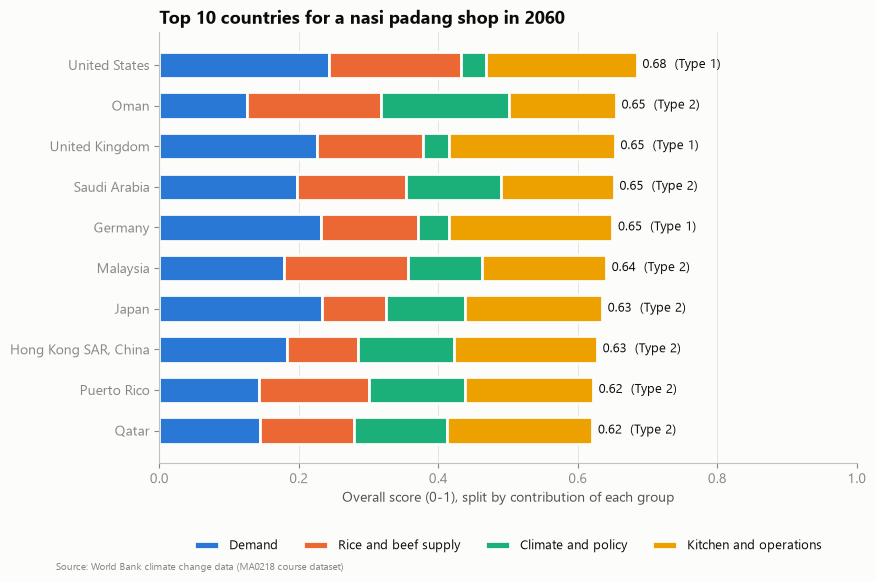

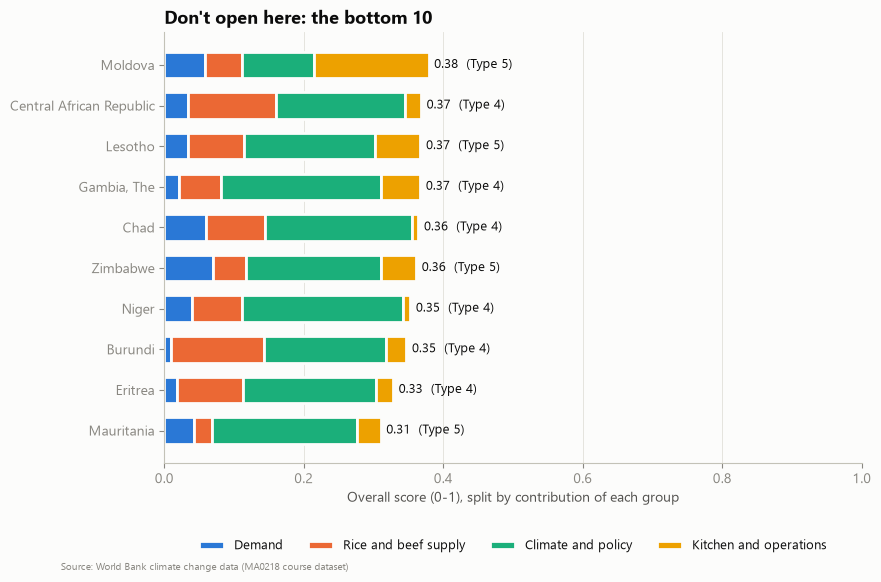

In [26]:
def stacked(rows, title, name):
    contrib = group_scores.loc[rows.index, GROUPS] * weights
    fig, ax = plt.subplots(figsize=(9, 0.42 * len(rows) + 1.4))
    left = np.zeros(len(rows))
    labels = rows["name"].values
    for i, g in enumerate(GROUPS):
        ax.barh(labels, contrib[g].values, left=left, color=CAT[i], height=0.65, label=g, edgecolor=SURFACE,
                linewidth=2)
        left += contrib[g].values
    for i, (v, c) in enumerate(zip(rows["score"].values, rows["cluster"].values)):
        ax.text(v + 0.008, i, f"{v:.2f}  (Type {c})", va="center", fontsize=9, color=INK)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel("Overall score (0-1), split by contribution of each group")
    ax.grid(axis="y", visible=False)
    ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12 - 0.3 / len(rows)), fontsize=9)
    ax.set_title(title)
    save(fig, name)


stacked(R.head(10), "Top 10 countries for a nasi padang shop in 2060", "10_top10")
stacked(R.tail(10), "Don't open here: the bottom 10", "11_bottom10")

### Robustness: does the top of the list survive different priorities?

Equal weights are a judgement call. We draw 5,000 random weightings of the four groups (uniformly over all
possible weightings) and count how often each country lands in the top 10.

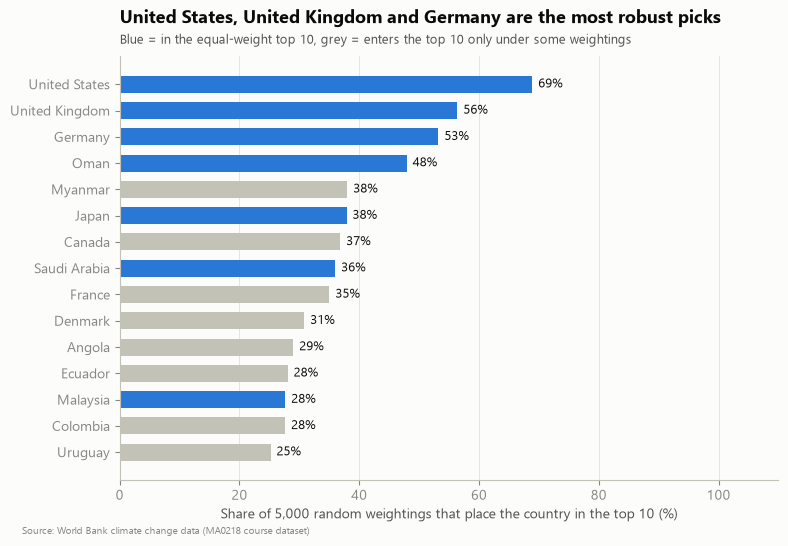

In [27]:
rng = np.random.default_rng(SEED)
W = rng.dirichlet(np.ones(len(GROUPS)), size=5000)
draw_scores = group_scores.loc[R.index, GROUPS].values @ W.T
draw_ranks = (-draw_scores).argsort(axis=0).argsort(axis=0) + 1
top10_share = pd.Series((draw_ranks <= 10).mean(axis=1), index=R.index)
R["top10_share"] = top10_share

show = R.nlargest(15, "top10_share").iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.barh(show["name"], show["top10_share"] * 100, color=[CAT[0] if r <= 10 else AXIS for r in show["rank"]],
        height=0.65)
for i, v in enumerate(show["top10_share"].values * 100):
    ax.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=9, color=INK)
ax.set_xlim(0, 110)
ax.set_xlabel("Share of 5,000 random weightings that place the country in the top 10 (%)")
ax.grid(axis="y", visible=False)
robust = R.nlargest(3, "top10_share")["name"].tolist()
titled(ax, f"{', '.join(robust[:2])} and {robust[2]} are the most robust picks",
       "Blue = in the equal-weight top 10, grey = enters the top 10 only under some weightings")
save(fig, "12_weight_sensitivity")

### Sanity check

Nasi padang already thrives in Indonesia, Malaysia and Singapore (common knowledge, used only as a check, not as data).
Where do they land?

In [28]:
check = R[R["name"].isin(["Indonesia", "Malaysia", "Singapore"])]
check[["name", "rank", "score", "top10_share", "cluster"]].assign(out_of=len(R))

,name,rank,score,top10_share,cluster,out_of
Country code,,,,,,
MYS,Malaysia,6,0.640491,0.2764,2,156
SGP,Singapore,23,0.591480,0.1332,2,156
IDN,Indonesia,54,0.543136,0.0000,2,156


## 8. Feature table export

The final country table (all features, cluster and rank) is saved for the slides and for teammates.

In [29]:
export = pd.concat([R[["name", "rank", "score", "cluster", "top10_share"]], group_scores.loc[R.index, GROUPS],
                    R[FEATURE_COLS]], axis=1).rename(columns=LABELS)
export.to_csv("nasipadang_ranking.csv", index_label="country_code")
print(f"Saved nasipadang_ranking.csv ({len(export)} countries)")

Saved nasipadang_ranking.csv (156 countries)


## 9. Conclusions

**Answer.** The strongest 2060 markets are rich, easy-to-operate countries with large urban populations. The
United States, United Kingdom and Germany are the most robust picks across weightings. Malaysia, where nasi
padang already thrives, lands in the top 10, which is a useful sanity check.

**Insights for the story**
- **Big-city all-rounders (Type 2) dominate the top 10.** The best markets combine city customers with
  *low* beef-tax risk, not just wealth.
- **The Gulf states score highly for a specific reason:** they are rich, rank well for ease of doing business,
  and have made no climate pledges, so beef is unlikely to be regulated. That is a genuine
  finding of the beef-tax-risk feature, and also its main caveat (pledges can change).
- **Methane cuts both ways:** it signals cheap local rice and beef today, and regulatory risk tomorrow.
- **Rendang advantage is real but sits in poor countries** (Type 4), which lose on demand and operations.
  It is the counterweight to the rich-country tilt of the other features.

**Limitations**
- Country-level data, so the answer is a country, not a city or a street.
- Methane is only reported up to 2005; the proxy is weak for fossil-fuel producers (handled by rule).
- Climate-commitment flags reflect pledges as of 2011.
- The neural-network imputer beats KNN and the iterative MLP only narrowly; its clear win is over
  filling with the average.
- Clusters overlap (silhouette about 0.2); weights are a judgement call, which the sensitivity check addresses.